<a href="https://colab.research.google.com/github/SoumyaShailja/spiky_ml/blob/main/3_House_Price_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##1. Linear Regression
##2. XG Boost
##3. Random Forest Regressor

My Objective: try every possible model and see which gives the best results.
Later go into details like feature dimensionality and complexity

Importing Dependencies

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import sklearn.datasets
from xgboost import XGBRegressor
from sklearn import metrics
import seaborn as sns

In [ ]:
house_price_dataset = sklearn.datasets.fetch_california_housing()

In [ ]:
print(house_price_dataset)

{'data': array([[   8.3252    ,   41.        ,    6.98412698, ...,    2.55555556,
          37.88      , -122.23      ],
       [   8.3014    ,   21.        ,    6.23813708, ...,    2.10984183,
          37.86      , -122.22      ],
       [   7.2574    ,   52.        ,    8.28813559, ...,    2.80225989,
          37.85      , -122.24      ],
       ...,
       [   1.7       ,   17.        ,    5.20554273, ...,    2.3256351 ,
          39.43      , -121.22      ],
       [   1.8672    ,   18.        ,    5.32951289, ...,    2.12320917,
          39.43      , -121.32      ],
       [   2.3886    ,   16.        ,    5.25471698, ...,    2.61698113,
          39.37      , -121.24      ]]), 'target': array([4.526, 3.585, 3.521, ..., 0.923, 0.847, 0.894]), 'frame': None, 'target_names': ['MedHouseVal'], 'feature_names': ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude'], 'DESCR': '.. _california_housing_dataset:\n\nCalifornia Housing dataset\n-

In [ ]:
X_house_price_dataset = pd.DataFrame(house_price_dataset['data'], columns = house_price_dataset['feature_names'])
Y_house_price_dataset = pd.DataFrame(house_price_dataset['target'], columns = house_price_dataset['target_names'])

In [ ]:
X_house_price_dataset.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


In [ ]:
print(X_house_price_dataset.info(), Y_house_price_dataset.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   MedInc      20640 non-null  float64
 1   HouseAge    20640 non-null  float64
 2   AveRooms    20640 non-null  float64
 3   AveBedrms   20640 non-null  float64
 4   Population  20640 non-null  float64
 5   AveOccup    20640 non-null  float64
 6   Latitude    20640 non-null  float64
 7   Longitude   20640 non-null  float64
dtypes: float64(8)
memory usage: 1.3 MB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 1 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedHouseVal  20640 non-null  float64
dtypes: float64(1)
memory usage: 161.4 KB
None None


DATA PREP

In [ ]:
from sklearn.preprocessing import MinMaxScaler

X_train, X_test, y_train, y_test = train_test_split(X_house_price_dataset, Y_house_price_dataset, test_size = 0.1, random_state = 1)

print(X_train.shape, y_train.shape, X_test.shape, y_test.shape)

scaler = MinMaxScaler()
X_train_2 = scaler.fit_transform(X_train)
X_test_2 = scaler.fit_transform(X_test)

(18576, 8) (18576, 1) (2064, 8) (2064, 1)


##LINEAR REGRESSION

In [ ]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train_2, y_train)

model.coef_

array([[  6.34722735,   0.48615936, -15.30443254,  21.87442016,
         -0.16377705,  -4.46176722,  -3.98258022,  -4.38907225]])

In [ ]:
y_training = model.predict(X_train_2)
y_testing = model.predict(X_test_2)

Evaluation Training set

In [ ]:
# Calculate performance metrics
mae = metrics.mean_absolute_error(y_train, y_training)
mse = metrics.mean_squared_error(y_train, y_training)
# rmse = metrics.mean_squared_error(y_train, y_training, squared=False)
r2 = metrics.r2_score(y_train, y_training)

# Print results
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Mean Squared Error (MSE): {mse:.4f}")
# print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"R-squared (R2 Score): {r2:.4f}")

Mean Absolute Error (MAE): 0.5310
Mean Squared Error (MSE): 0.5229
R-squared (R2 Score): 0.6068


Evaluate Test set

In [ ]:

# 4. Calculate performance metrics
mae = metrics.mean_absolute_error(y_test, y_testing)
mse = metrics.mean_squared_error(y_test, y_testing)
# rmse = mean_squared_error(y_test, y_testing, squared=False)
r2 = metrics.r2_score(y_test, y_testing)

# Print results
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Mean Squared Error (MSE): {mse:.4f}")
# print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"R-squared (R2 Score): {r2:.4f}")

Mean Absolute Error (MAE): 0.6757
Mean Squared Error (MSE): 0.9308
R-squared (R2 Score): 0.3078


In [ ]:
X_test.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2064 entries, 4712 to 13061
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   MedInc      2064 non-null   float64
 1   HouseAge    2064 non-null   float64
 2   AveRooms    2064 non-null   float64
 3   AveBedrms   2064 non-null   float64
 4   Population  2064 non-null   float64
 5   AveOccup    2064 non-null   float64
 6   Latitude    2064 non-null   float64
 7   Longitude   2064 non-null   float64
dtypes: float64(8)
memory usage: 145.1 KB


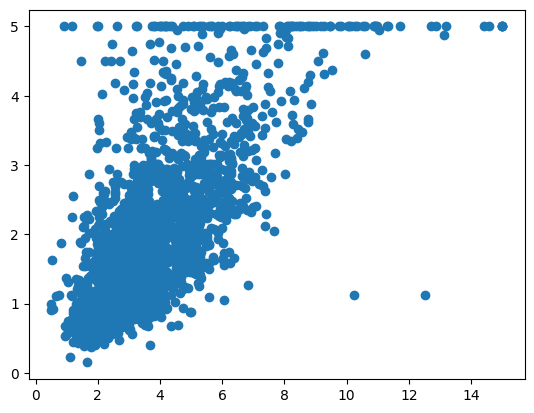

In [ ]:
plt.scatter(X_test['MedInc'],y_test)

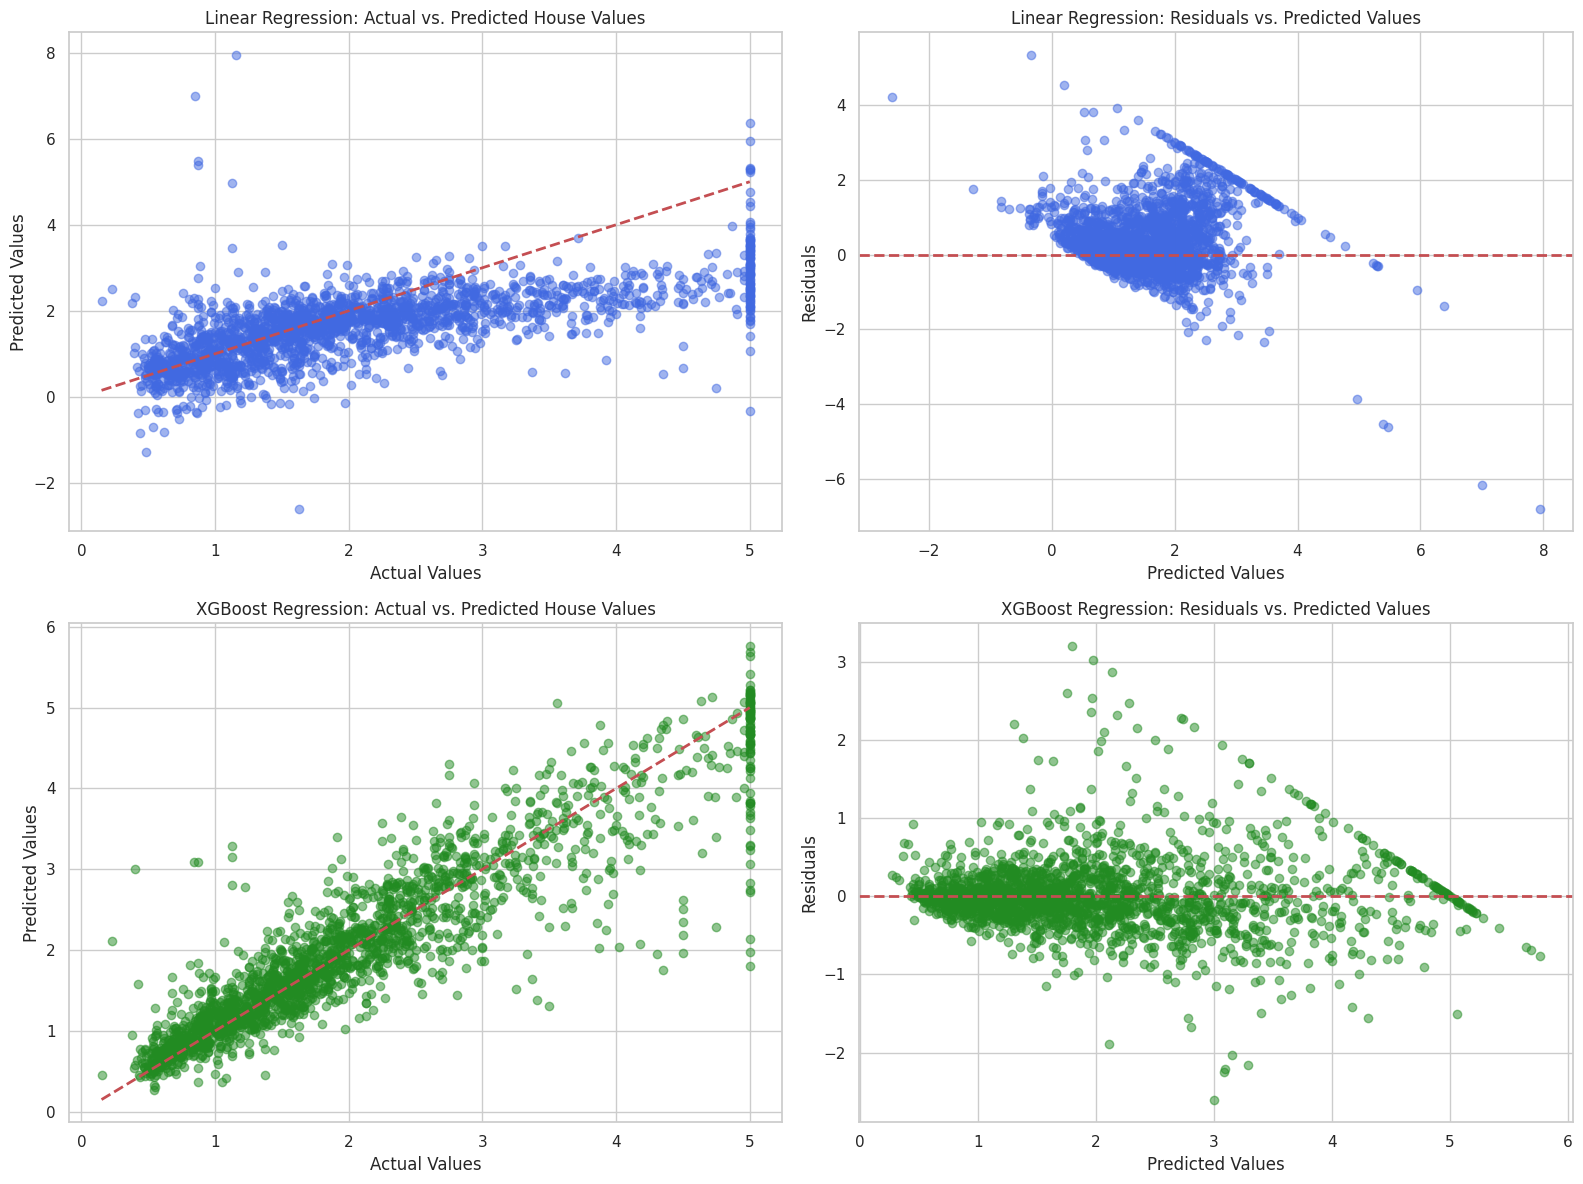

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set up the plotting style and layout
sns.set_theme(style='whitegrid')
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# --- LINEAR REGRESSION PLOTS ---
# Actual vs Predicted
axes[0, 0].scatter(y_test, y_testing, alpha=0.5, color='royalblue')
axes[0, 0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
axes[0, 0].set_title('Linear Regression: Actual vs. Predicted House Values')
axes[0, 0].set_xlabel('Actual Values')
axes[0, 0].set_ylabel('Predicted Values')

# Residuals Plot
linear_residuals = y_test.values.flatten() - y_testing.flatten()
axes[0, 1].scatter(y_testing, linear_residuals, alpha=0.5, color='royalblue')
axes[0, 1].axhline(y=0, color='r', linestyle='--', lw=2)
axes[0, 1].set_title('Linear Regression: Residuals vs. Predicted Values')
axes[0, 1].set_xlabel('Predicted Values')
axes[0, 1].set_ylabel('Residuals')

# --- XGBOOST REGRESSION PLOTS ---
# Actual vs Predicted
axes[1, 0].scatter(y_test, y_test_model, alpha=0.5, color='forestgreen')
axes[1, 0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
axes[1, 0].set_title('XGBoost Regression: Actual vs. Predicted House Values')
axes[1, 0].set_xlabel('Actual Values')
axes[1, 0].set_ylabel('Predicted Values')

# Residuals Plot
xgb_residuals = y_test.values.flatten() - y_test_model
axes[1, 1].scatter(y_test_model, xgb_residuals, alpha=0.5, color='forestgreen')
axes[1, 1].axhline(y=0, color='r', linestyle='--', lw=2)
axes[1, 1].set_title('XGBoost Regression: Residuals vs. Predicted Values')
axes[1, 1].set_xlabel('Predicted Values')
axes[1, 1].set_ylabel('Residuals')

plt.tight_layout()
plt.show()

##XGBOOST REGRESSION

In [ ]:
X_house_price_dataset.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


In [ ]:
Y_house_price_dataset.head()

,MedHouseVal
0,4.526
1,3.585
2,3.521
3,3.413
4,3.422


<Axes: >

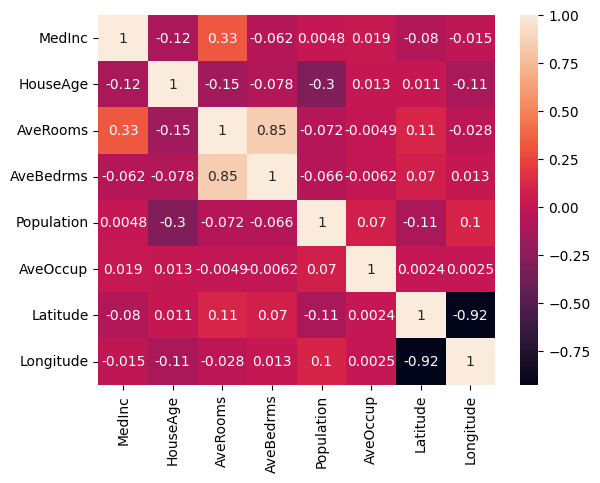

In [ ]:
correlation = X_house_price_dataset.corr()
sns.heatmap(correlation, annot = True)

In [ ]:
model = XGBRegressor()
model.fit(X_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=None, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=None,
             n_jobs=None, num_parallel_tree=None, ...)

In [ ]:
y_train_model = model.predict(X_train)
y_test_model = model.predict(X_test)

In [ ]:
print(y_train_model)

[3.979066  1.2068543 1.6514974 ... 1.0421228 1.3480716 1.1583982]


Evaluation

In [ ]:
#training data accuracy

r2 = metrics.r2_score(y_train, y_train_model)
mse = metrics.mean_squared_error(y_train, y_train_model)

print(r2)
print(mse)

0.9407837390899658
0.07875557243824005


In [ ]:
#testing data accuracy

r2 = metrics.r2_score(y_test, y_test_model)
mse = metrics.mean_squared_error(y_test, y_test_model)

print(r2)
print(mse)

0.8363047242164612
0.22012680768966675


##RANDOM FOREST REGRESSION

In [ ]:
# https://www.datacamp.com/tutorial/random-forest-regression

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
import matplotlib.pyplot as plt

# X_train, X_test, y_train, y_test = train_test_split(X_house_price_dataset, Y_house_price_dataset, test_size = 0.1, random_state = 1)
# scaler = MinMaxScaler()
# X_train_2 = scaler.fit_transform(X_train)
# X_test_2 = scaler.fit_transform(X_test)

model = RandomForestRegressor(random_state=42)
model.fit(X_train, y_train)


/usr/local/lib/python3.13/dist-packages/sklearn/base.py:1389: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


RandomForestRegressor(random_state=42)

In [ ]:
#Validation on Training data
y_pred_train = model.predict(X_train)

mae = mean_absolute_error(y_train, y_pred_train)
rmse = root_mean_squared_error(y_train, y_pred_train)
r2 = r2_score(y_train, y_pred_train)

print("Mean Absolute Error: ", mae)
print("RMSE: ", rmse)
print("R2: ", r2)

Mean Absolute Error:  0.12016035000538369
RMSE:  0.18672121459529922
R2:  0.9737851751283653


In [ ]:
#Validation on Testing data
y_pred_test = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred_test)
rmse = root_mean_squared_error(y_test, y_pred_test)
r2 = r2_score(y_test, y_pred_test)

print("Mean Absolute Error: ", mae)
print("RMSE: ", rmse)
print("R2: ", r2)

Mean Absolute Error:  0.31625535968992263
RMSE:  0.5017188370984265
R2:  0.8128093951492047


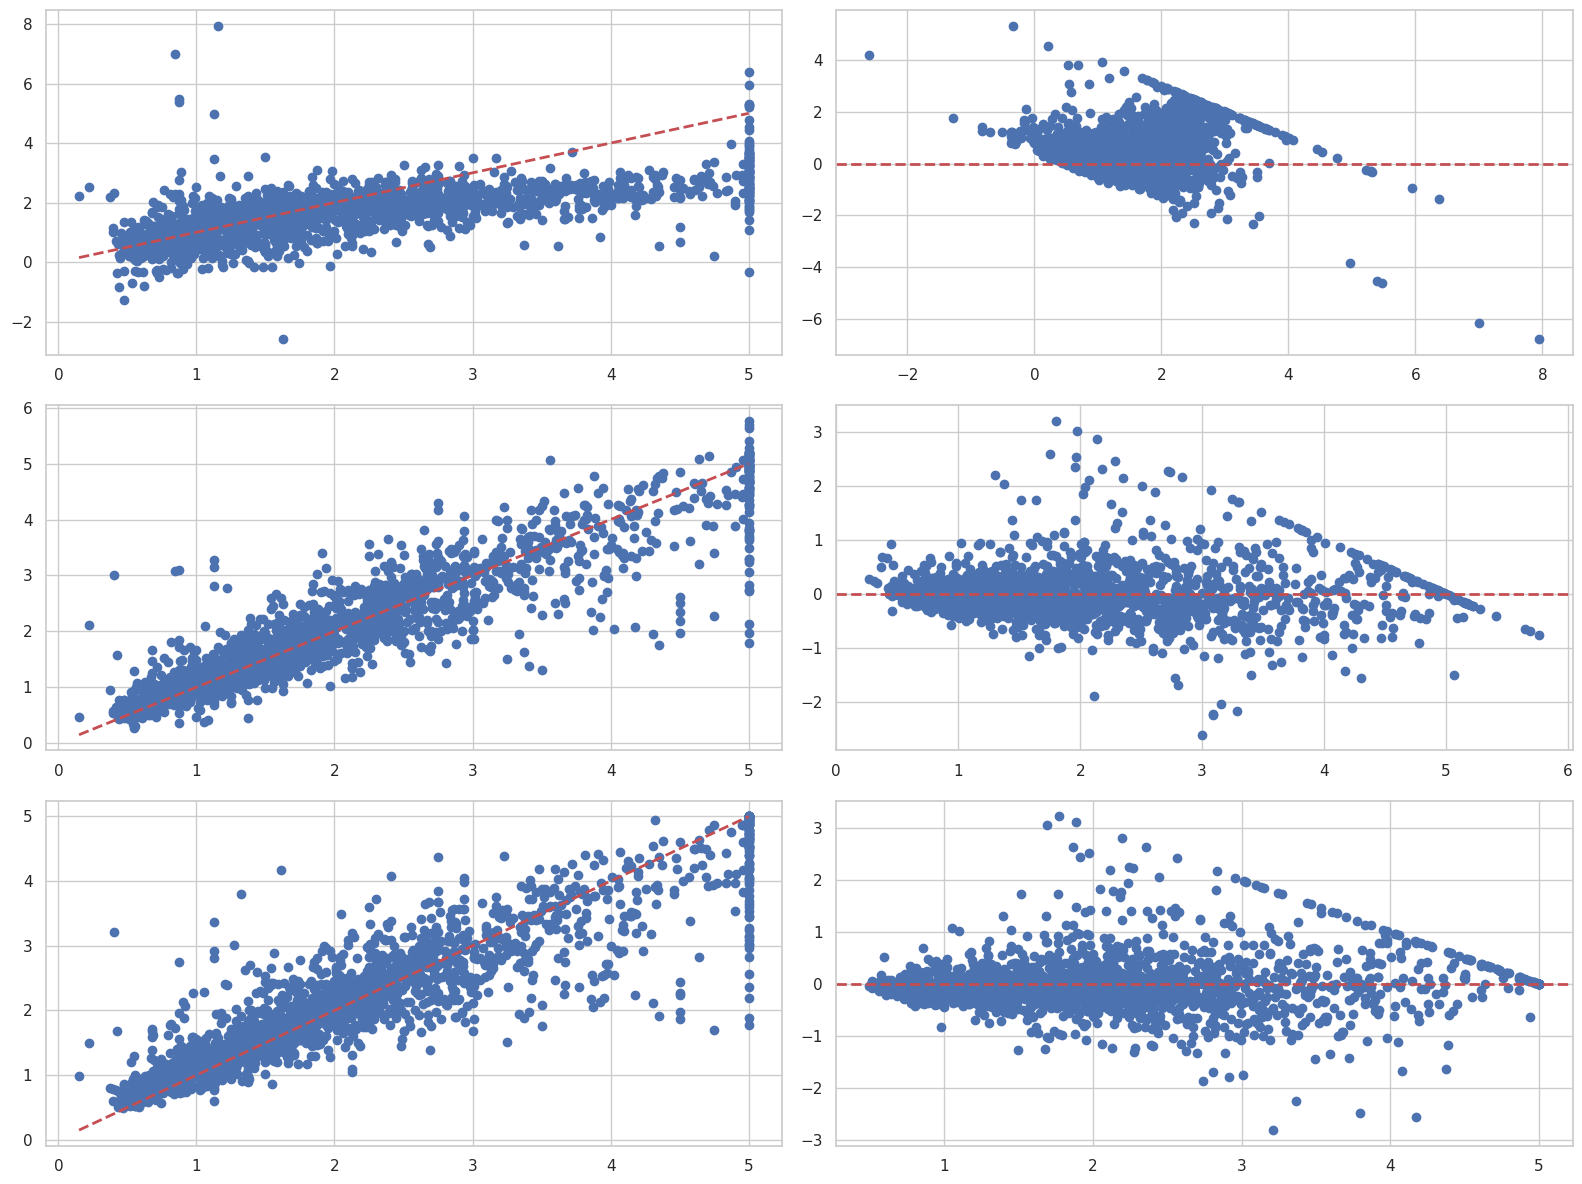

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set up the plotting style and layout
sns.set_theme(style='whitegrid')
fig, axes = plt.subplots(3, 2, figsize=(16, 12))

# --- LINEAR REGRESSION PLOTS ---
# Actual vs Predicted
axes[0, 0].scatter(y_test, y_testing)
axes[0, 0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
# axes[0, 0].plot([y_testing.min(), y_testing.max()], [y_testing.min(), y_testing.max()], 'g--', lw=2)


# Residuals Plot
linear_residuals = y_test.values.flatten() - y_testing.flatten()
axes[0, 1].scatter(y_testing, linear_residuals)
axes[0, 1].axhline(y=0, color='r', linestyle='--', lw=2)

# --- XGBOOST REGRESSION PLOTS ---
# Actual vs Predicted
axes[1, 0].scatter(y_test, y_test_model)
axes[1, 0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)


# Residuals Plot
xgb_residuals = y_test.values.flatten() - y_test_model
axes[1, 1].scatter(y_test_model, xgb_residuals)
axes[1, 1].axhline(y=0, color='r', linestyle='--', lw=2)

# --- Random Forest REGRESSION PLOTS ---
# Actual vs Predicted
axes[2, 0].scatter(y_test, y_pred_test)
axes[2, 0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)


# Residuals Plot
xgb_residuals = y_test.values.flatten() - y_pred_test
axes[2, 1].scatter(y_pred_test, xgb_residuals)
axes[2, 1].axhline(y=0, color='r', linestyle='--', lw=2)

plt.tight_layout()
plt.show()